# 02 · Mean reversion with RSI

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kolyamkl/qm-fintech-quant-workshop/blob/main/notebooks/02_rsi_mean_reversion.ipynb)

*QM FinTech Society quant workshop · Led by **Adnan Salehin** (Lead SWE & VP, JPMorgan)*

The moving-average crossover **follows trends**. This strategy does the opposite: it **bets that big moves snap back** — *buy the dip, sell the rip*.

In [1]:
# ▶ Setup — run this cell first.
# In Google Colab it downloads the workshop repo; on your laptop it just finds the code.
import os, subprocess, sys

REPO = "qm-fintech-quant-workshop"
if "google.colab" in sys.modules and os.path.basename(os.getcwd()) != REPO:
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", f"https://github.com/kolyamkl/{REPO}.git"], check=True)
    os.chdir(REPO)
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")  # the code lives one folder up from notebooks/
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

# Re-load your edited .py files automatically (handy when you change strategies/template.py)
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import pandas as pd
pd.set_option("display.precision", 4)

## RSI in one minute

The **Relative Strength Index** compares recent up-moves with recent down-moves and squeezes the result into 0–100:
- **below 30** → the price fell a lot recently ("oversold") → buy
- **above 70** → it rose a lot recently ("overbought") → sell
- in between → keep what we have

The code is short — see `strategies/rsi_mean_reversion.py`.

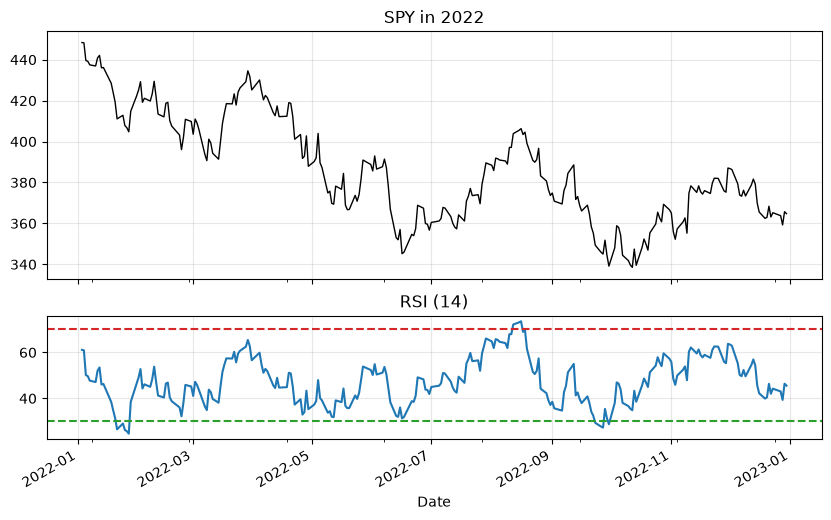

In [2]:
from backtester import load_prices, run_backtest
from backtester.plotting import plot_signals
from strategies import ma_crossover, rsi, rsi_mean_reversion

spy = load_prices("SPY")
spy_rsi = rsi(spy["Close"], period=14)

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
spy["Close"].loc["2022"].plot(ax=top, color="black", linewidth=1, title="SPY in 2022")
spy_rsi.loc["2022"].plot(ax=bottom, title="RSI (14)")
bottom.axhline(30, linestyle="--", color="tab:green")
bottom.axhline(70, linestyle="--", color="tab:red")
top.grid(alpha=0.3); bottom.grid(alpha=0.3)
plt.show()

## Backtest it

In [3]:
positions = rsi_mean_reversion(spy, period=14, lower=30, upper=70)
result = run_backtest(spy, positions, cost_bps=5)
result.summary()

,Strategy,Buy & hold
Total return,98.8%,360.6%
Annual return (CAGR),6.6%,15.3%
Annual volatility,14.1%,17.7%
Sharpe ratio,0.52,0.89
Max drawdown,-28.3%,-33.7%
Number of trades,10,—
Win rate,90.0%,—


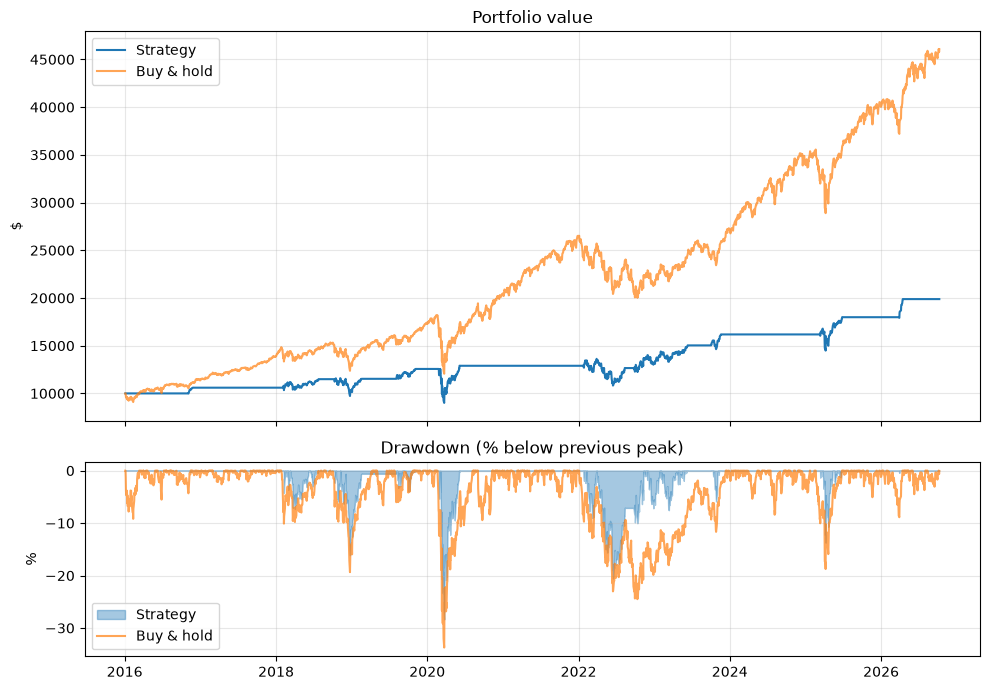

In [4]:
result.plot()

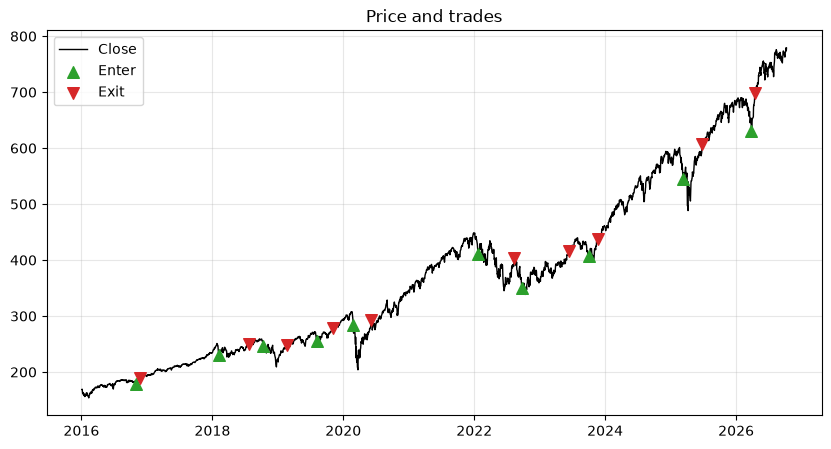

In [5]:
plot_signals(spy, result)

**✏️ Try it:** change `lower` and `upper` (e.g. 20/80 or 35/65). Do you trade more or less? What happens to the win rate?

## Trend following vs mean reversion

Neither style wins everywhere — trend following likes long, steady moves; mean reversion likes choppy, sideways markets. Let's compare both strategies (with default settings) on several tickers:

In [6]:
rows = []
for ticker in ["SPY", "QQQ", "IWM", "XLU", "XLE", "GLD", "TLT", "AAPL"]:
    prices = load_prices(ticker)
    ma = run_backtest(prices, ma_crossover(prices))
    rs = run_backtest(prices, rsi_mean_reversion(prices))
    rows.append({
        "Ticker": ticker,
        "Buy & hold Sharpe": ma.benchmark_metrics["Sharpe ratio"],
        "MA crossover Sharpe": ma.metrics["Sharpe ratio"],
        "RSI Sharpe": rs.metrics["Sharpe ratio"],
    })

pd.DataFrame(rows).set_index("Ticker").round(2) + 0.0  # + 0.0 turns "-0.00" into "0.00"

,Buy & hold Sharpe,MA crossover Sharpe,RSI Sharpe
Ticker,,,
SPY,0.89,0.75,0.52
QQQ,0.95,0.98,0.67
IWM,0.55,0.19,0.32
XLU,0.58,0.39,0.53
XLE,0.53,0.50,0.41
GLD,0.83,0.61,0.27
TLT,-0.01,0.00,-0.10
AAPL,1.00,0.71,0.77


**Questions to discuss:**
- On which tickers does each strategy do best? Do those assets trend or chop around?
- Does either strategy beat buy-and-hold consistently? (Be honest — this is the most common result in quant research!)
- How could you combine the two ideas? (One of the exercises in `docs/resources.md`.)